# The degeneracy of $\lambda$ in Hall & Hooker's section 3.2

Section 3.2 of Hall & Hooker (2016) chooses the penalty $\lambda$ by how well the fitted
procedure reconstructs a parametric stand-in $\tilde b_{\mathrm{simp}}$ for the coefficient
function. Run as its displays are written, that rule returns the smallest candidate on the grid
whatever the data: the penalty does nothing, and what is left is an unpenalised endpoint scan.

The cause is three separate errors of scale, each in a quantity the paper defines precisely
enough to check, so none of what follows is a matter of interpretation.

1. **The variance terms of $S_Y^B$, $S_b^B$ and $S_b^A$ are $n$ times too large.** A
   coefficient fitted to $n$ curves has variance $\hat\sigma^2/(n\tau_j)$, so the displayed
   $\hat\sigma^2 \sum_j (\tau_j)^{-1}$ overstates it by $n$ once $\tau_j$ is read, as any FPCA
   routine returns it, as an eigenvalue of the covariance operator. $S_b^B$ is out by a second
   factor: it is governed by the full-interval eigenvalues $\tau_j^1$ that $\check b^*$ was
   estimated from, not the truncated $\tau_j^\theta$, and only the latter diverges as
   $\theta \to 0$.
2. **$\lambda$ changes scale between (3.4) and step 6.** The penalty is written $n\lambda\theta^2$
   in one display and $\lambda\theta^2$ in the next, so the $\lambda$ that reaches $V(\lambda)$ is
   $n$ times too small to move it.
3. **Step 7 integrates a density finer than the grid it is given.** $\sqrt{V}$ is below the
   spacing of the $\theta$ grid under either reading of $\lambda$, so the trapezium rule samples
   $S_b$ where it is asked to average it.

Everything below is one dataset from the paper's own Section 4 recipe unless a cell says
otherwise. `truncFLR` implements the three corrections; this notebook reconstructs the displays
as written in order to compare them.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fts_research.truncFLR import HH, HH_A, HH_dgp
from fts_research.truncFLR import _common as C

plt.rcParams["figure.figsize"] = (10, 3.6)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

u, v = 0.8, 1.0
lambdas = np.linspace(0.0, 1.0, 250)[1:]
data = HH_dgp.sim_dataset(n=200, n_grid=301, u=u, v=v, snr=26.25, rng=5)
grid, Y = data["grid"], data["Y"]
X = data["X"][:, ::-1]                 # mirrored, so the true endpoint is theta = 1 - u
n = len(Y)
a_pilot, b_pilot, fpc = HH.pilot_fpca(X, Y, grid)
lam_hat, diag = HH.lambda_select(X, Y, grid, a_pilot, b_pilot, fpc, None, lambdas)
theta_grid, sigma2 = diag["theta_grid"], diag["sigma2"]
h = theta_grid[1] - theta_grid[0]

print(f"n = {n}, grid spacing h = {h:.5f}, true theta = {1 - u:.1f}")
print(f"BIC-selected components m = {fpc['m']}, pilot residual variance = {sigma2:.5f}")
print(f"step-3 parametric cutoff theta_bar = {diag['theta_bar']:.3f}")

n = 200, grid spacing h = 0.00333, true theta = 0.2
BIC-selected components m = 8, pilot residual variance = 0.00312
step-3 parametric cutoff theta_bar = 0.200


## The symptom

Steps 4'–7 are reconstructed here twice. `displayed` evaluates $S_Y^B$ and $S_b^B$ exactly as
step 5' writes them; the shipped criterion differs from it only in the variance terms, so the
bias terms are shared and taken from the same diagnostics. `replay` then runs steps 6' and 7 on
whichever pair it is handed, under either reading of $\lambda$ and with the step-7 integral
either taken on the $\theta$ grid or refined to resolve its density.

In [2]:
def displayed(diag, X, grid, n):
    """S_Y^B and S_b^B as step 5' displays them, from the shipped criterion's own pieces.

    The variance terms are the only difference: the shipped S_Y^B carries sigma^2/(n tau_j^1)
    where the display writes sigma^2/tau_j^1, and the shipped S_b^B is governed by tau_j^1
    where the display writes the truncated tau_j^theta.

    Returns S_Y^B and S_b^B on the criterion's theta grid (arrays).

    PARAMETERS
    diag : dict, the diagnostics `HH.lambda_select` returns, whose bias terms are shared;
    n    : int, sample size, the factor the displayed variance terms are out by.
    """
    tg, phi, s2 = diag["theta_grid"], diag["phi"], diag["sigma2"]
    S_b = np.empty(len(tg))
    for q, theta in enumerate(tg):
        interval = grid <= theta
        phi2 = np.trapezoid(phi[:, interval] ** 2, grid[interval], axis=1)
        tau_theta = C.trunc_eigvals(X, grid, interval, len(phi))
        S_b[q] = diag["bias_b"][q] + s2 * np.sum(phi2 / tau_theta)
    return diag["bias_Y"] + n * diag["var_Y"], S_b


def first_min(v):
    """Step 6's endpoint rule: the first interior local minimum, else the global one."""
    return next((k for k in range(1, len(v) - 1) if v[k] <= v[k - 1] and v[k] <= v[k + 1]),
                int(np.argmin(v)))


def replay(S_Y, S_b, theta_grid, lambdas, n, sigma2, lam_scale, resolve):
    """Steps 6' and 7 over the candidate lambdas.

    Returns lam_hat (float), and P_b, V and theta_lambda at each candidate (arrays).

    PARAMETERS
    lam_scale : str, "per observation" divides S_Y'' by n before pairing it with lambda, the
                reading under which one lambda serves both step-6 displays; "total" is the
                literal one, S_Y as steps 5 and 5' sum it;
    resolve   : bool, integrate step 7 on a grid refined to the width of the weight rather
                than on the theta grid it is displayed on.
    """
    step = theta_grid[1] - theta_grid[0]
    P_b, V = np.full(len(lambdas), np.nan), np.full(len(lambdas), np.nan)
    theta_lam = np.empty(len(lambdas))
    for j, lam in enumerate(lambdas):
        idx = first_min(S_Y + n * lam * theta_grid ** 2)
        theta_lam[j] = theta_grid[idx]
        k = min(max(idx, 1), len(theta_grid) - 2)
        curv = (S_Y[k + 1] - 2 * S_Y[k] + S_Y[k - 1]) / step ** 2
        if lam_scale == "per observation":
            curv = curv / n
        if curv <= 0:
            continue
        V[j] = (sigma2 / n) * curv / (curv + lam) ** 2
        P_b[j] = (C.weighted_S_b(S_b, theta_grid, theta_grid[idx], V[j], C.normal_weight)
                  if resolve else
                  np.trapezoid(S_b * C.normal_weight(theta_grid, theta_grid[idx], V[j]),
                               theta_grid))
    return {"lam_hat": lambdas[int(np.nanargmin(P_b))], "P_b": P_b, "V": V,
            "theta_lam": theta_lam}


S_Y_disp, S_b_disp = displayed(diag, X, grid, n)
paper = replay(S_Y_disp, S_b_disp, theta_grid, lambdas, n, sigma2, "total", False)
print(f"section 3.2 as displayed: lambda_hat = {paper['lam_hat']:.5f}, "
      f"smallest candidate = {lambdas[0]:.5f}")
print(f"P_b increasing in lambda throughout: "
      f"{bool(np.all(np.diff(paper['P_b'][~np.isnan(paper['P_b'])]) > 0))}")

section 3.2 as displayed: lambda_hat = 0.00402, smallest candidate = 0.00402
P_b increasing in lambda throughout: True


That is not one unlucky seed. The cache below holds, for each of 25 independent datasets, the
shipped criterion, its displayed counterpart, and the endpoint scan $\mathrm{RSS}(\theta)$ that
step 3.1.2 minimises. Every table in this notebook is read off it, so no configuration is ever
compared against a different draw.

In [3]:
N_SEEDS = 25
cache = []
for seed in range(N_SEEDS):
    d = HH_dgp.sim_dataset(n=200, n_grid=301, u=u, v=v, snr=26.25, rng=seed)
    Xs, Ys, gs = d["X"][:, ::-1], d["Y"], d["grid"]
    a_s, b_s, fpc_s = HH.pilot_fpca(Xs, Ys, gs)
    _, dg = HH.lambda_select(Xs, Ys, gs, a_s, b_s, fpc_s, None, lambdas)
    SY_d, Sb_d = displayed(dg, Xs, gs, n)
    _, tg_s, rss = HH.theta_methodB(Xs, Ys, gs, a_s, b_s, 0.0)     # penalty-free scan
    cache.append({"data": d, "X": Xs, "pilot": (a_s, b_s), "diag": dg,
                  "S_Y_disp": SY_d, "S_b_disp": Sb_d, "theta_grid": tg_s, "rss": rss})

floor_hits = sum(replay(c["S_Y_disp"], c["S_b_disp"], c["diag"]["theta_grid"], lambdas,
                        n, c["diag"]["sigma2"], "total", False)["lam_hat"] == lambdas[0]
                 for c in cache)
print(f"lambda_hat on the grid floor, section 3.2 as displayed: {floor_hits}/{N_SEEDS} seeds")

lambda_hat on the grid floor, section 3.2 as displayed: 25/25 seeds


## What steps 4'–5' define

Step 4' fits $(\check a^*, \check b^*)$ once, on the whole interval, to the noiseless target
$\bar Y^*_i = \check a + \int \tilde b_{\mathrm{simp}} X_i$, in the pilot's own components
$\hat\phi^1_j$. Step 5' then defines two conditional expectations over the noise of the
hypothetical data $Y^*_i = \bar Y^*_i + \epsilon^*_i$, $\epsilon^* \sim N(0, \hat\sigma^2)$,

$$S_Y^B(\theta) = E\Big[\textstyle\sum_i \{\bar Y^*_i - \check Y^*_i(\theta)\}^2 \,\Big|\, \mathcal{X}\Big],
\qquad
S_b^B(\theta) = E\Big[\int_I (\tilde b_{\mathrm{simp}} - \check b^*\,I(t<\theta))^2 \,\Big|\, \mathcal{X}\Big].$$

Both are quantities, not conventions, and both follow from one fact. The scores
$\xi_{ij} = \int \hat\phi^1_j X_i$ satisfy $\sum_i (\xi_{ij} - \bar\xi_j)^2 = n\tau_j^1$, since
$\tau_j^1$ is an eigenvalue of the *covariance* operator — a variance per curve, not a sum of
squares — so least squares gives

$$\operatorname{var}(\check\beta^*_j)
= \frac{\hat\sigma^2}{\sum_i (\xi_{ij} - \bar\xi_j)^2} = \frac{\hat\sigma^2}{n\,\tau_j^1}.$$

Truncation at $\theta$ does not re-estimate anything; it only changes what that one piece of
coefficient noise is read through. Through the $n$ truncated predictions it appears with
loadings $\int_0^\theta \hat\phi^1_j X_i$, and through $\check b^*I(t<\theta)$ with loadings
$\int_0^\theta (\hat\phi^1_j)^2$, the components being orthonormal on $I$ but not on
$[0,\theta]$. So

$$S_Y^B(\theta) = \sum_i \{\bar Y^*_i - \check Y^*_i(\theta)\}^2
 + \frac{\hat\sigma^2}{n}\sum_{j=1}^m \frac{1}{\tau_j^1} \sum_i \Big(\int_0^\theta \hat\phi^1_j X_i\Big)^2,
\qquad
S_b^B(\theta) = \int_I (\tilde b_{\mathrm{simp}} - \check b^* I)^2
 + \frac{\hat\sigma^2}{n}\sum_{j=1}^m \frac{1}{\tau_j^1}\int_0^\theta (\hat\phi^1_j)^2 .$$

The displays carry no $1/n$, and write $\tau_j^\theta$ in place of $\tau_j^1$ in $S_b^B$. Since
both are expectations, simulating $\epsilon^*$ settles which is right.

In [4]:
rng = np.random.default_rng(0)
phi, tau = fpc["phi"], fpc["tau"]
b_simp = diag["b_simp"]
Ybar_star = a_pilot + np.trapezoid(b_simp[None, :] * X, grid, axis=1)

# Step 4' as a least-squares fit, so its noise can be simulated directly.
scores = np.trapezoid(phi[:, None, :] * X[None, :, :], grid, axis=2).T
design = np.column_stack([np.ones(n), scores])
gram_inv = np.linalg.inv(design.T @ design)
noise = rng.standard_normal((n, 20000)) * np.sqrt(sigma2)
coefs = gram_inv @ design.T @ (Ybar_star[:, None] + noise)         # (m + 1, reps)

print(f"{'theta':>6} | {'S_Y simulated':>14} {'displayed':>11} {'shipped':>10} "
      f"| {'S_b simulated':>14} {'displayed':>11} {'shipped':>10}")
for theta in (0.1, 0.2, 0.3, 0.5, 0.8):
    q = int(np.argmin(np.abs(theta_grid - theta)))
    interval = grid <= theta_grid[q]
    load = np.column_stack([np.ones(n), np.trapezoid(phi[:, None, interval]
                                                     * X[None, :, interval],
                                                     grid[interval], axis=2).T])
    mc_S_Y = np.mean(np.sum((Ybar_star[:, None] - load @ coefs) ** 2, axis=0))
    b_hat = np.where(interval[None, :], coefs[1:].T @ phi, 0.0)
    mc_S_b = np.mean(np.trapezoid((b_simp[None, :] - b_hat) ** 2, grid, axis=1))
    print(f"{theta:6.2f} | {mc_S_Y:14.5f} {S_Y_disp[q]:11.3f} {diag['S_Y'][q]:10.5f} "
          f"| {mc_S_b:14.5f} {S_b_disp[q]:11.3g} {diag['S_b'][q]:10.5f}")

 theta |  S_Y simulated   displayed    shipped |  S_b simulated   displayed    shipped


  0.10 |        5.54890       6.154    5.54496 |        0.10046    2.23e+05    0.10046


  0.20 |        0.23581       1.407    0.23227 |        0.01199        26.5    0.01199


  0.30 |        0.10722       1.700    0.10396 |        0.01635        0.94    0.01635


  0.50 |        0.12556       2.661    0.12251 |        0.01677       0.288    0.01677


  0.80 |        0.11919       4.177    0.11626 |        0.01721       0.186    0.01721


The shipped column is the simulated one; the displayed column is not. $S_Y^B$ as displayed is
out by the factor $n = 200$ at every $\theta$. $S_b^B$ is out by orders of magnitude that grow as
$\theta$ falls, which is the second error rather than the first: $\tau_j^\theta \to 0$ as the
sub-interval shrinks, so the displayed variance diverges exactly where the estimator's variance
is in fact *smallest*, less of $\check b^*$ being retained.

Two approximations separate the shipped column from the simulated one, both of them in the
paper's display rather than in the correction. It keeps only the diagonal of
$\operatorname{cov}(\check\beta^*)$, whose off-diagonal entries are $O(n^{-1})$ relative; and it
omits the intercept's contribution to the summed prediction variance, which is $\hat\sigma^2$
exactly — the constant gap visible in the $S_Y$ columns. Being free of $\theta$, that constant
cannot move $\theta_\lambda$ or the curvature of $S_Y$, so it is left where the paper puts it.

One term in section 3.2 is written without a $\tau$, and it is the one that needs no correction:
method A's $S_Y^A$ carries $\hat\sigma^2(m+1)$, exactly $\hat\sigma^2\operatorname{tr}(H)$ for an
$(m+1)$-parameter fit. The displays are consistent with each other only under the reading taken
here, and `tests/test_scaling.py` pins all four against the expectations above.

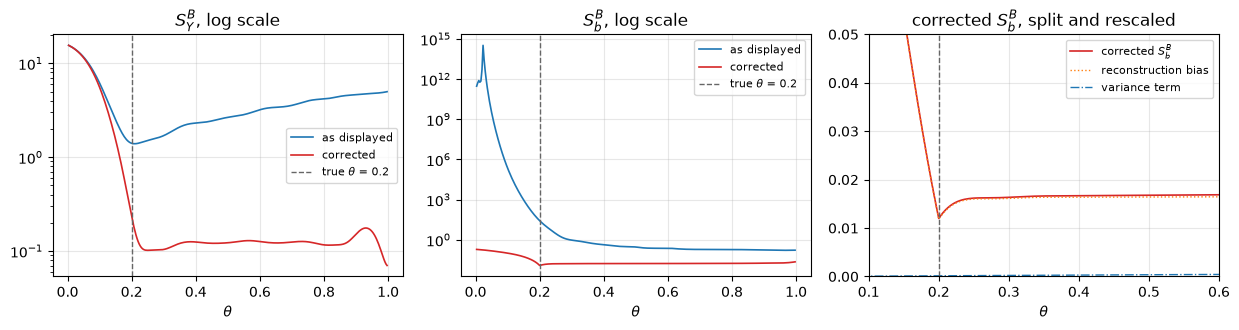

displayed S_b spans 2.06e+15 and is minimised at theta = 0.963
corrected S_b spans 15.9 and is minimised at theta = 0.200
global minimiser of S_Y: displayed 0.210, corrected 0.997


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(12.5, 3.4))
for a_, (disp, ship, name) in zip(ax, [(S_Y_disp, diag["S_Y"], r"$S_Y^B$"),
                                       (S_b_disp, diag["S_b"], r"$S_b^B$")]):
    a_.semilogy(theta_grid, disp, color="C0", lw=1.2, label="as displayed")
    a_.semilogy(theta_grid, ship, color="C3", lw=1.2, label="corrected")
    a_.axvline(1 - u, color="0.4", ls="--", lw=1, label=fr"true $\theta$ = {1 - u:.1f}")
    a_.set_xlabel(r"$\theta$"); a_.set_title(f"{name}, log scale"); a_.legend(fontsize=8)

# The corrected S_b on its own scale, where the trade-off the criterion needs is visible.
ax[2].plot(theta_grid, diag["S_b"], color="C3", lw=1.2, label=r"corrected $S_b^B$")
ax[2].plot(theta_grid, diag["bias_b"], color="C1", lw=1, ls=":", label="reconstruction bias")
ax[2].plot(theta_grid, diag["var_b"], color="C0", lw=1, ls="-.", label="variance term")
ax[2].axvline(1 - u, color="0.4", ls="--", lw=1)
ax[2].set_xlim(0.1, 0.6); ax[2].set_ylim(0, 0.05)
ax[2].set_xlabel(r"$\theta$"); ax[2].set_title(r"corrected $S_b^B$, split and rescaled")
ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"displayed S_b spans {S_b_disp.max() / S_b_disp.min():.3g} and is minimised at "
      f"theta = {theta_grid[np.argmin(S_b_disp)]:.3f}")
print(f"corrected S_b spans {diag['S_b'].max() / diag['S_b'].min():.3g} and is minimised at "
      f"theta = {theta_grid[np.argmin(diag['S_b'])]:.3f}")
print(f"global minimiser of S_Y: displayed {theta_grid[np.argmin(S_Y_disp)]:.3f}, "
      f"corrected {theta_grid[np.argmin(diag['S_Y'])]:.3f}")

The first mechanism is in the middle panel. The displayed $S_b^B$ spans fifteen orders of
magnitude and decreases across essentially the whole grid, its divergent variance term swamping
the reconstruction bias everywhere. A larger $\lambda$ moves $\theta_\lambda$ left, and left is
where the displayed $S_b$ is better, so $P_b(\lambda)$ can only increase and $\hat\lambda$ is the
smallest candidate offered.

The right-hand panel is the same $S_b^B$ on the corrected scale, split into its two terms. The
variance term is now a small increasing correction rather than a divergence, and the criterion
is carried by the reconstruction bias, which turns down at the true endpoint. That is a shape
$\lambda$ can be chosen against.

The left-hand panel corroborates the reading from the paper's own text. Step 6' takes the
*first* interior minimum of $S_Y^B + n\lambda\theta^2$ rather than the global one because "there
tends to be a sharp drop in $S_Y^B(\theta)$ close to the right-hand end point of the interval, so
$S_Y^B(\theta) + \lambda\theta^2$ is minimized at $\theta = 1$ unless $\lambda$ is very large".
That is a description of the corrected curve, whose global minimiser sits at the right-hand end.
The displayed curve has its global minimum in the interior, and the rule the paper gives for it
would be unnecessary.

## The second error: $\lambda$ changes scale between (3.4) and step 6

Equation (3.4) penalises with $n\lambda\theta^2$, the $n$ inserted because "both $S$ and $S_1$
are of order $n$". Step 6 then writes $S_Y + \lambda\theta^2$, and

$$V(\lambda) = \frac{\hat\sigma^2}{n}\,\frac{S_Y''(\theta_\lambda)}{\{S_Y''(\theta_\lambda) + \lambda\}^2},$$

again with a bare $\lambda$. One $\lambda$ can serve both displays only if the $S_Y$ of step 6 is
the per-observation error $S_Y/n$; and that is also the only reading under which $V$ is of order
$\hat\sigma^2/n$, the order of the variance of an estimator, rather than $\hat\sigma^2/n^2$.

What $\lambda$ can do to $V$ is set by the ratio $\lambda/S_Y''$, and reading $S_Y$ as a sum
divides that ratio by $n$.

In [6]:
curv = np.gradient(np.gradient(diag["S_Y"], h), h)[first_min(diag["S_Y"])]
corrected = replay(diag["S_Y"], diag["S_b"], theta_grid, lambdas, n, sigma2,
                   "per observation", True)
sum_read = replay(diag["S_Y"], diag["S_b"], theta_grid, lambdas, n, sigma2, "total", True)

print(f"curvature of S_Y at theta_lambda: {curv:8.4f} summed over i, "
      f"{curv / n:.4f} per observation")
print(f"candidate lambdas: [{lambdas[0]:.4g}, {lambdas[-1]:.4g}]\n")
print(f"{'reading of S_Y in step 6':22} {'(S_Y__ + lambda) / S_Y__':>26} "
      f"{'sd of the weight':>18} {'grid points per sd':>20}")
for name, c, r in (("as a sum", curv, sum_read),
                   ("per observation", curv / n, corrected)):
    sd = np.sqrt(np.nanmedian(r["V"]))
    span = f"[{(c + lambdas[0]) / c:.4f}, {(c + lambdas[-1]) / c:.4f}]"
    print(f"{name:22} {span:>26} {sd:18.6f} {sd / h:20.2f}")

curvature of S_Y at theta_lambda:  14.6846 summed over i, 0.0734 per observation
candidate lambdas: [0.004016, 1]

reading of S_Y in step 6   (S_Y__ + lambda) / S_Y__   sd of the weight   grid points per sd
as a sum                         [1.0003, 1.0681]           0.000131                 0.04
per observation                 [1.0547, 14.6197]           0.001670                 0.50


Across the whole candidate grid, the summed reading lets $\lambda$ change the denominator of
$V$ by at most a few percent, where the per-observation reading changes it by more than a factor
of fourteen. The penalty is not weak under the first reading; it is absent. And the density step
7 is asked to integrate is narrower by $\sqrt{n}$.

## The third error: step 7 integrates a density the grid cannot see

$$P_b(\lambda) = \int_I S_b(\theta)\,\frac{1}{\sqrt{2\pi V(\lambda)}}
\exp\Big\{-\frac{(\theta-\theta_\lambda)^2}{2V(\lambda)}\Big\}\,d\theta$$

is displayed on the same $\theta$ grid as $S_b$, and under either reading of $\lambda$ the weight
is narrower than that grid's spacing: twenty-five times narrower as a sum, twice as narrow per
observation.

How much that costs is not a matter of judgement. The trapezium rule applied to a Gaussian
centred on a grid point is exact up to aliasing, and Poisson summation gives the factor in
closed form:

$$h\sum_k \varphi(\theta_k;\theta_\lambda,V) \;=\; \sum_{m \in \mathbb{Z}} e^{-2\pi^2 m^2 V/h^2}
\;=\; 1 + 2e^{-2\pi^2 V/h^2} + \dots$$

So the rule is *spectrally* accurate while $\sqrt{V} \gtrsim h/2$, where that factor is $1.014$,
and fails completely once $\sqrt{V} \ll h$, where the same series sums to $h/\sqrt{2\pi V}$ and
the integral is a single sample:

$$P_b(\lambda) \;\longrightarrow\; \frac{h}{\sqrt{2\pi V(\lambda)}}\,S_b(\theta_\lambda),$$

which is not an average of $S_b$ at all. `_common.weighted_S_b` integrates on a grid refined to
the width of the weight instead, which is accurate in both regimes.

configuration      sd / h  on grid / resolved  Poisson factor  P_b / S_b(theta_lam)
as displayed        0.039             10.2877         10.2999               10.2999
corrected           0.501              1.0140          1.0141                1.0174


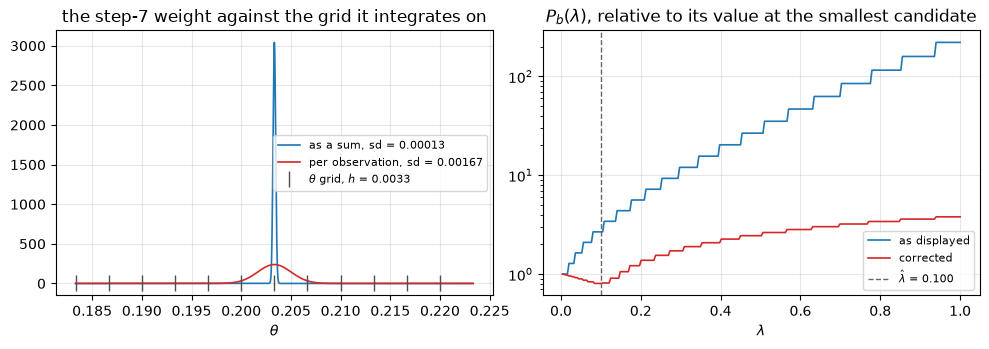

In [7]:
def aliasing(V, h, terms=200):
    """Poisson-summation factor by which the trapezium rule overstates a Gaussian integral.

    Returns the factor (float), which is 1 + 2 exp(-2 pi^2 V / h^2) to leading order and
    h / sqrt(2 pi V) in the limit of a weight much finer than the grid.
    """
    m = np.arange(1, terms + 1)
    return float(1 + 2 * np.sum(np.exp(-2 * np.pi ** 2 * m ** 2 * V / h ** 2)))


print(f"{'configuration':16} {'sd / h':>8} {'on grid / resolved':>19} {'Poisson factor':>15} "
      f"{'P_b / S_b(theta_lam)':>21}")
for name, S_Y, S_b, scale in (("as displayed", S_Y_disp, S_b_disp, "total"),
                              ("corrected", diag["S_Y"], diag["S_b"], "per observation")):
    args = (S_Y, S_b, theta_grid, lambdas, n, sigma2, scale)
    on_grid, fine = replay(*args, False), replay(*args, True)
    ok = ~np.isnan(on_grid["P_b"])
    V = np.median(on_grid["V"][ok])
    sampled = np.interp(on_grid["theta_lam"][ok], theta_grid, S_b)
    print(f"{name:16} {np.sqrt(V) / h:8.3f} "
          f"{np.median(on_grid['P_b'][ok] / fine['P_b'][ok]):19.4f} {aliasing(V, h):15.4f} "
          f"{np.median(on_grid['P_b'][ok] / sampled):21.4f}")

unresolved = replay(diag["S_Y"], diag["S_b"], theta_grid, lambdas, n, sigma2,
                    "per observation", False)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
centre = corrected["theta_lam"][int(np.nanargmin(corrected["P_b"]))]
fine = np.linspace(centre - 0.02, centre + 0.02, 2001)
for name, r, colour in (("as a sum", sum_read, "C0"), ("per observation", corrected, "C3")):
    V = np.nanmedian(r["V"])
    ax[0].plot(fine, C.normal_weight(fine, centre, V), color=colour, lw=1.2,
               label=fr"{name}, sd = {np.sqrt(V):.5f}")
on_grid = theta_grid[np.abs(theta_grid - centre) <= 0.02]
ax[0].plot(on_grid, np.zeros_like(on_grid), "|", color="0.3", ms=12,
           label=fr"$\theta$ grid, $h$ = {h:.4f}")
ax[0].set_xlabel(r"$\theta$")
ax[0].set_title("the step-7 weight against the grid it integrates on")
ax[0].legend(fontsize=8)

for name, r, colour in (("as displayed", paper, "C0"), ("corrected", corrected, "C3")):
    ax[1].semilogy(lambdas, r["P_b"] / r["P_b"][0], color=colour, lw=1.2, label=name)
ax[1].axvline(corrected["lam_hat"], color="0.4", ls="--", lw=1,
              label=fr"$\hat\lambda$ = {corrected['lam_hat']:.3f}")
ax[1].set_xlabel(r"$\lambda$")
ax[1].set_title(r"$P_b(\lambda)$, relative to its value at the smallest candidate")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

The aliasing factor is the measured one in both regimes. Run as displayed, the step-7 integral
overstates itself tenfold and returns exactly $h\,S_b(\theta_\lambda)/\sqrt{2\pi V}$ — and that
magnification is not a harmless constant, since $V$ moves with the curvature of $S_Y$ at
$\theta_\lambda$. What step 7 then ranks is $S_b$ at one point, tilted by a factor carrying a
$\theta_\lambda$ of its own.

With $\lambda$ on the scale of (3.4), $\sqrt{V}$ is half the grid spacing and the same rule is
accurate to $1.4\%$. Refining the quadrature is worth a percent or so here rather than an order
of magnitude — but it is what makes $P_b$ an average whatever $V$ turns out to be, and $V$ is
not something the criterion controls.

## What each correction is worth

The three are separable, so each can be applied on its own. The endpoint columns come from
minimising $\mathrm{RSS}(\theta) + n\hat\lambda\theta^2$ at each configuration's own
$\hat\lambda$, over the same 25 datasets; only $\hat\lambda$ differs between rows.

In [8]:
CONFIGS = [("as displayed",           "displayed", "total",           False),
           ("variance scale only",    "corrected", "total",           False),
           ("lambda scale only",      "displayed", "per observation", False),
           ("quadrature only",        "displayed", "total",           True),
           ("+ variance and lambda",  "corrected", "per observation", False),
           ("all three",              "corrected", "per observation", True)]

print(f"{'configuration':24} {'interior lambda':>16} {'median lambda':>14} "
      f"{'bias(u)':>9} {'sd(u)':>8} {'RMSE(u)':>9}")
for name, which, scale, resolve in CONFIGS:
    lams, errs = [], []
    for c in cache:
        dg = c["diag"]
        S_Y, S_b = ((c["S_Y_disp"], c["S_b_disp"]) if which == "displayed"
                    else (dg["S_Y"], dg["S_b"]))
        r = replay(S_Y, S_b, dg["theta_grid"], lambdas, n, dg["sigma2"], scale, resolve)
        theta_hat = c["theta_grid"][first_min(c["rss"] + n * r["lam_hat"]
                                              * c["theta_grid"] ** 2)]
        lams.append(r["lam_hat"])
        errs.append((1.0 - theta_hat) - c["data"]["u"])
    lams, errs = np.array(lams), np.array(errs)
    print(f"{name:24} {str(int((lams > lambdas[0]).sum())) + '/' + str(N_SEEDS):>16} "
          f"{np.median(lams):14.4f} {errs.mean():+9.4f} {errs.std(ddof=1):8.4f} "
          f"{np.sqrt((errs ** 2).mean()):9.4f}")

configuration             interior lambda  median lambda   bias(u)    sd(u)   RMSE(u)
as displayed                         0/25         0.0040   -0.0335   0.0068    0.0341


variance scale only                  0/25         0.0040   -0.0335   0.0068    0.0341
lambda scale only                   16/25         0.0080   -0.0287   0.0075    0.0296


quadrature only                     13/25         0.0080   -0.0299   0.0078    0.0308
+ variance and lambda               23/25         0.1004   -0.0012   0.0138    0.0136


all three                           23/25         0.1004   -0.0023   0.0130    0.0130


Rescaling the variance terms on its own changes nothing at all, and the reason is instructive.
With $V$ collapsed, $P_b$ is still $h\,S_b(\theta_\lambda)/\sqrt{2\pi V(\theta_\lambda)}$, and
that is not $S_b$ but $S_b$ divided by a width that varies with $\theta_\lambda$ through the
curvature of $S_Y$; the ranking it produces need not follow $S_b$ even where $S_b$ has been put
right. A criterion has to be reading its own surrogate before improving the surrogate can help.

Either of the other two on its own restores that much, on 16 and 13 of the 25 seeds, but the
$\hat\lambda$ they pick is then chosen against an $S_b$ that still falls across the whole grid:
larger $\lambda$ keeps looking better, $\theta_\lambda$ is pushed too far left, and the endpoint
comes back short by 0.0287 — some nine grid steps. Only with all three does $\hat\lambda$ sit
inside the candidate grid on nearly every seed, and the endpoint lose its bias and two-thirds of
its root mean squared error.

## What it buys the estimator

The endpoint is a means to a coefficient function, so the last comparison is the integrated
squared error of $\hat b$ against the untruncated pilot the method starts from — the paper's own
Table 2 comparison. Method A is included because its $S_b^A$ carries the same missing $1/n$;
its $S_Y^A$, alone among the four displays, does not.

In [9]:
def ise(b_hat, d):
    """Integrated squared error of a coefficient estimate against the truth. Returns a float."""
    return np.trapezoid((b_hat - d["b"]) ** 2, d["grid"])


rows = {}
for name, which, scale, resolve in (("B, as displayed", "displayed", "total", False),
                                    ("B, corrected", "corrected", "per observation", True)):
    errs, ises, lams = [], [], []
    for c in cache:
        dg, d = c["diag"], c["data"]
        S_Y, S_b = ((c["S_Y_disp"], c["S_b_disp"]) if which == "displayed"
                    else (dg["S_Y"], dg["S_b"]))
        r = replay(S_Y, S_b, dg["theta_grid"], lambdas, n, dg["sigma2"], scale, resolve)
        theta_hat = c["theta_grid"][first_min(c["rss"] + n * r["lam_hat"]
                                              * c["theta_grid"] ** 2)]
        _, b_hat = HH.ab_methodB(theta_hat, d["grid"], *c["pilot"], c["X"], Y=d["Y"])
        errs.append((1.0 - theta_hat) - d["u"])
        ises.append(ise(b_hat[::-1], d))
        lams.append(r["lam_hat"])
    rows[name] = (np.array(errs), np.array(ises), np.array(lams))

errs, ises, lams = [], [], []
for c in cache:
    d = c["data"]
    res = HH_A.fit_mirror(d["X"], d["Y"], d["grid"], lambdas)
    errs.append(res["u_hat"] - d["u"])
    ises.append(ise(res["b_hat"], d))
    lams.append(res["lam_hat"])
rows["A, corrected"] = (np.array(errs), np.array(ises), np.array(lams))

pilot_ise = np.array([ise(HH.pilot_fpca(c["data"]["X"], c["data"]["Y"],
                                        c["data"]["grid"])[1], c["data"]) for c in cache])

print(f"{N_SEEDS} datasets, n = {n}, 301 grid points, signal-to-noise 26.25\n")
print(f"{'method':>16} {'bias(u)':>9} {'sd(u)':>8} {'RMSE(u)':>9} {'mean ISE':>10} "
      f"{'sd ISE':>9} {'interior lambda':>16}")
for name, (e, i, lam) in rows.items():
    interior = f"{int((lam > lambdas[0]).sum())}/{N_SEEDS}"
    print(f"{name:>16} {e.mean():+9.4f} {e.std(ddof=1):8.4f} {np.sqrt((e ** 2).mean()):9.4f} "
          f"{i.mean():10.4f} {i.std(ddof=1):9.4f} {interior:>16}")
print(f"{'no truncation':>16} {'':>9} {'':>8} {'':>9} {pilot_ise.mean():10.4f} "
      f"{pilot_ise.std(ddof=1):9.4f}")

25 datasets, n = 200, 301 grid points, signal-to-noise 26.25

          method   bias(u)    sd(u)   RMSE(u)   mean ISE    sd ISE  interior lambda
 B, as displayed   -0.0335   0.0068    0.0341     0.0111    0.0048             0/25
    B, corrected   -0.0023   0.0130    0.0130     0.0084    0.0061            23/25
    A, corrected   -0.0019   0.0094    0.0094     0.0094    0.0057            10/25
   no truncation                                  0.0219    0.0019


Both methods beat the untruncated pilot, as the paper's Table 2 reports for its own settings.
What method B gains is the endpoint: run as displayed it pays for a penalty chosen at the floor
of the grid, and the window it keeps is systematically about nine grid steps too short. Method A
is reported corrected only; one of its two surrogates was mis-scaled rather than both, and the
endpoint it recovers is close to method B's corrected one.

Method A also chooses a floor $\hat\lambda$ far more often than method B does, and that costs it
little. Method B's frozen pilot is fitted on the whole interval, so the penalty is the only thing
pulling $\hat\theta$ back from the right-hand end where $S_Y^B$ drops away. Method A refits
$(a, b)$ on $[0, \theta]$ at every candidate, so an over-long window is already paid for in the
fit itself; $\lambda\theta^2$ has less left to do, and choosing it badly matters less.

## What the corrected criterion is actually choosing

Worth being clear about what has been repaired. $S_b$ measures reconstruction of
$\tilde b_{\mathrm{simp}}$, the step-3 parametric stand-in, which is fitted with a cutoff
$\bar\theta$ of its own by unpenalised least squares. Its bias term is minimised where the
truncation matches that cutoff, and on the corrected scale the bias term is what dominates. So
step 7 largely selects the $\lambda$ whose $\theta_\lambda$ lands nearest $\bar\theta$.

In [10]:
gap = np.array([c["diag"]["theta_grid"][np.argmin(c["diag"]["S_b"])] - c["diag"]["theta_bar"]
                for c in cache])
share = np.array([c["diag"]["var_b"][np.argmin(c["diag"]["S_b"])]
                  / c["diag"]["S_b"][np.argmin(c["diag"]["S_b"])] for c in cache])
print(f"S_b minimised at theta_bar exactly, over the {N_SEEDS} seeds: "
      f"{int((np.abs(gap) <= h).sum())}/{N_SEEDS} within one grid step")
print(f"median |argmin S_b - theta_bar| = {np.median(np.abs(gap)):.4f} "
      f"(grid spacing {h:.4f})")
print(f"variance term's median share of S_b at its minimum = {np.median(share):.4f}")

S_b minimised at theta_bar exactly, over the 25 seeds: 25/25 within one grid step
median |argmin S_b - theta_bar| = 0.0000 (grid spacing 0.0033)
variance term's median share of S_b at its minimum = 0.0123


That is the section 3.2 design rather than a residue of the errors above: the paper chooses
$\lambda$ "on the basis of our ability to reconstruct a parametric model
$\tilde b_{\mathrm{simp}}$", and says so. It does mean the rule inherits whatever
$\tilde b_{\mathrm{simp}}$ gets wrong — the paper's own §4 finds a case, $\theta = 0.75$ against
a two-turning-point $b$, where a one-frequency $\tilde b_{\mathrm{simp}}$ costs both methods
substantially. Where there is no truth to check against, `HH_A.truncation_profile` answers the
same question from held-out prediction instead.

## Summary

Section 3.2 is arithmetically sound and, as displayed, unusable. Three scale errors, all in
quantities the paper defines precisely enough to check:

- **$S_Y^B$, $S_b^B$ and $S_b^A$** carry variance terms $n$ times the variance the estimators
  have, since $\hat\sigma^2/(n\tau_j)$ is what least squares gives a coefficient fitted to $n$
  curves. $S_b^B$ additionally reads $\tau_j^\theta$ where the estimator's variance is set by
  $\tau_j^1$, which turns a term that should shrink with $\theta$ into one that diverges. The
  effect is that $S_b$ decreases over the whole grid, so $P_b$ increases in $\lambda$ and
  $\hat\lambda$ goes to the floor.
- **$\lambda$** is paired with a summed $S_Y$ in step 6 and with a per-observation one in (3.4),
  differing by $n$. Under the summed reading $\lambda$ cannot move $V$, which collapses to order
  $\hat\sigma^2/n^2$.
- **Step 7** is integrated on the $\theta$ grid, which is coarser than $\sqrt{V}$ under either
  reading, so $P_b$ samples $S_b$ where it should average it — as displayed, returning
  $S_b(\theta_\lambda)$ magnified by a $\lambda$-dependent $h/\sqrt{2\pi V}$.

Corrected, the criterion does what section 3.2 describes: $S_Y^B$ drops away at the right-hand
end, so step 6' needs the first-minimum rule the paper gives it; $S_b^B$ turns down at the true
endpoint instead of diverging at zero; $P_b$ is an average of $S_b$ with an interior minimiser;
and $\hat\lambda$ lands inside the candidate grid on 23 of 25 seeds. The endpoint estimate loses
its bias and two-thirds of its root mean squared error, and the coefficient function beats the
untruncated pilot it started from.